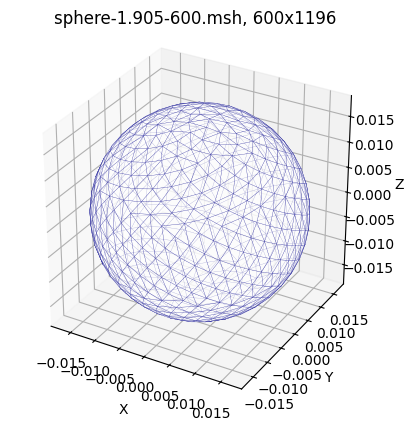

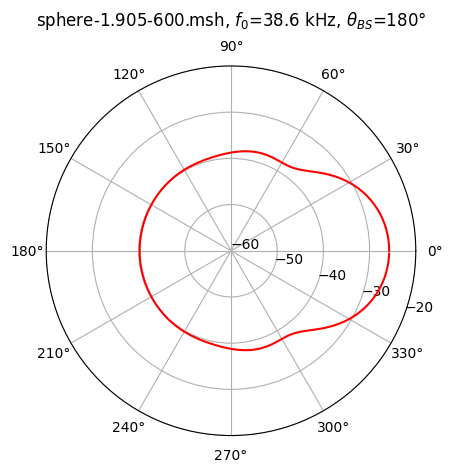

# sphere-1.905-600.msh
# th0=0 ph0=0 f0=38600 c0=1480
0	0.0515261
1	0.0514956
2	0.0514045
3	0.0512532
4	0.051042
5	0.0507717
6	0.050443
7	0.0500571
8	0.0496151
9	0.0491184
10	0.0485686
11	0.0479674
12	0.0473166
13	0.0466183
14	0.0458747
15	0.0450881
16	0.0442608
17	0.0433955
18	0.0424949
19	0.0415617
20	0.0405988
21	0.0396093
22	0.038596
23	0.0375623
24	0.0365112
25	0.0354461
26	0.0343702
27	0.0332869
28	0.0321997
29	0.0311118
30	0.0300269
31	0.0289484
32	0.0278797
33	0.0268244
34	0.025786
35	0.0247679
36	0.0237738
37	0.022807
38	0.0218709
39	0.0209689
40	0.0201042
41	0.01928
42	0.0184993
43	0.0177646
44	0.0170786
45	0.0164432
46	0.01586
47	0.0153302
48	0.0148543
49	0.0144321
50	0.0140627
51	0.0137446
52	0.0134754
53	0.0132522
54	0.0130716
55	0.0129296
56	0.0128221
57	0.0127445
58	0.0126926
59	0.012662
60	0.0126485
61	0.0126482
62	0.0126576
63	0.0126735
64	0.0126929
65	0.0127134
66	0.0127329
67	0.0127496
68	0.012762
69	0.012769
70	0.0127697
71	0.0127634
72	0.0127499
73	0.0127287
74	0.0

In [ ]:
#!pip install -q numpy scipy matplotlib

datapath = "../msh/"

from numpy import pi, sqrt, exp, sin, cos, log10, array, zeros, linspace
from scipy.linalg import lu_factor, lu_solve
import matplotlib.pyplot as plt

fname = 'sphere-1.905-600.msh'
th = 0
f0 = 38.6e3
c0 = 1480

k = 2 * pi * f0 / c0
d = [cos(pi / 180 * th), sin(pi / 180 * th), 0]

with open(datapath+fname) as f: lines = f.readlines()
n = int(lines[4])
v = [list(map(float, lines[5+i].split()[1:4])) for i in range(n)]
m = int(lines[n + 7])
e = [list(map(lambda x:int(x)-1, lines[n+8+i].split()[5:8])) for i in range(m)]

x = [sum([array(v[e[i][j]]) / 3 for j in range(3)]) for i in range(m)] # use centers
#x, m = array(v), len(v) # use vertices (without triangles)

G = zeros((m, m), dtype=complex)
for i in range(m):
    for j in range(m):
        r = sqrt(sum((x[i] - x[j]) ** 2))
        G[i][j] = exp(1j * k * r) / r / (4*pi) if r != 0 else k / 4 + 1j * k / (4*pi)

f_inc = array([exp(1j * k * p @ d) for p in x])

phi = lu_solve(lu_factor(G), -f_inc)

r1 = [[cos(pi / 180 * i), sin(pi / 180 * i), 0] for i in range(360)]
G2 = [[exp(-1j * k * p @ r) / (4*pi) for p in x] for r in r1]
psc = G2 @ phi

# plot mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
tri = [[array(v[i]) for i in t] for t in e]
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
mesh_collection = Poly3DCollection(tri, alpha=0.6)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v_arr = array(v)
ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d"%(fname,n,m))
plt.savefig("soft_1.svg", format="svg", bbox_inches="tight")
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, color='red')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(r"%s, $f_0$=%g kHz, $\theta_{BS}$=%g$\degree$"%(fname,f0/1e3,th+180), va='bottom')
plt.savefig("soft_2.svg", format="svg", bbox_inches="tight")
plt.show()

# print
s = "# %s\n# th0=%g ph0=0 f0=%g c0=%g\n"%(fname,th,f0,c0)
s += "\n".join(["%d\t%g"%(i,abs(psc[i])) for i in range(len(psc))])
print(s)
with open("soft.txt", "w") as f: print(s,file=f)
